In [1]:
import sys
sys.path.append("..")

%load_ext autoreload
%autoreload 2

from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import root_mean_squared_error
from scipy.stats import pearsonr
from lightgbm import LGBMRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from src.data import load_fd001, add_rul, FEATURES
from src.validation import run_cv, oof_vorhersagen
from src.features import build_features, steigung, add_rolling, add_diff, add_slope

In [2]:
train, test, rul = load_fd001()
train = add_rul(train, cap = 125)

In [3]:
X = train[FEATURES]
y = train["RUL"]
gfk = GroupKFold(n_splits = 10)
splits = list(gfk.split(X, y, groups = train["unit"]))
cv_lr = run_cv(LinearRegression(), X, y, splits)
cv_lr.drop(columns="fold").agg(["mean", "std"])

,rmse_train,rmse_val,nasa_val,bias,anteil_spaet,max_spaet
mean,21.485017,21.560367,9.509827,0.000667,0.523391,53.144905
std,0.149752,1.333467,3.260342,3.562756,0.067326,7.055259


In [4]:
cv_xgb = run_cv(XGBRegressor(random_state=42), X,y, splits)
cv_xgb.drop(columns="fold").agg(["mean", "std"])

,rmse_train,rmse_val,nasa_val,bias,anteil_spaet,max_spaet
mean,11.950677,19.225841,18.774737,-0.096558,0.424170,76.982822
std,0.188642,2.442047,13.600800,2.923220,0.043026,11.040047


In [5]:
neue_spalten = []

for col in FEATURES:
    for w in [5,25]:
        name = f"{col}_mean{w}"
        train[name] = train.groupby("unit")[col].transform(lambda s: s.rolling(w, min_periods = 1).mean())
        neue_spalten.append(name)

        name = f"{col}_std{w}"
        train[name] = train.groupby("unit")[col].transform(lambda s: s.rolling(w,min_periods=1).std())
        neue_spalten.append(name)

feature_cols = FEATURES + neue_spalten

In [6]:
len(feature_cols)

70

In [7]:
train["s2_mean5"].equals(train["s2_mean25"])

False

In [8]:
train[neue_spalten].isna().sum()

s2_mean5        0
s2_std5       100
s2_mean25       0
s2_std25      100
s3_mean5        0
s3_std5       100
s3_mean25       0
s3_std25      100
s4_mean5        0
s4_std5       100
s4_mean25       0
s4_std25      100
s8_mean5        0
s8_std5       100
s8_mean25       0
s8_std25      100
s11_mean5       0
s11_std5      100
s11_mean25      0
s11_std25     100
s13_mean5       0
s13_std5      100
s13_mean25      0
s13_std25     100
s15_mean5       0
s15_std5      100
s15_mean25      0
s15_std25     100
s17_mean5       0
s17_std5      100
s17_mean25      0
s17_std25     100
s7_mean5        0
s7_std5       100
s7_mean25       0
s7_std25      100
s12_mean5       0
s12_std5      100
s12_mean25      0
s12_std25     100
s20_mean5       0
s20_std5      100
s20_mean25      0
s20_std25     100
s21_mean5       0
s21_std5      100
s21_mean25      0
s21_std25     100
s9_mean5        0
s9_std5       100
s9_mean25       0
s9_std25      100
s14_mean5       0
s14_std5      100
s14_mean25      0
s14_std25 

In [9]:
std_spalten = []

for name in neue_spalten:
    if "_std" in name:
        std_spalten.append(name)
        

In [10]:
len(std_spalten)

28

In [11]:
train[std_spalten] = train[std_spalten].fillna(0)

In [12]:
train[feature_cols].isna().sum().sum()

np.int64(0)

In [13]:
X2 = train[feature_cols]

In [14]:
cv_roll_xgb = run_cv(XGBRegressor(random_state=42),X2,y,splits)
cv_roll_xgb.drop(columns="fold").agg(["mean","std"])

,rmse_train,rmse_val,nasa_val,bias,anteil_spaet,max_spaet
mean,4.015343,17.187365,7.788014,-0.850030,0.436730,66.665333
std,0.049255,1.878350,2.727569,2.101363,0.041324,6.301363


In [15]:
cv_roll_lr = run_cv(LinearRegression(), X2, y, splits)
cv_roll_lr.drop(columns="fold").agg(["mean", "std"])

,rmse_train,rmse_val,nasa_val,bias,anteil_spaet,max_spaet
mean,17.841254,18.263552,6.039325,0.034131,0.507202,52.275315
std,0.083617,0.775009,1.180043,1.455382,0.039059,5.423435


In [16]:
(cv_roll_lr["rmse_val"]<cv_lr["rmse_val"]).sum()

np.int64(10)

In [17]:
(cv_roll_xgb["rmse_val"]<cv_xgb["rmse_val"]).sum()

np.int64(10)

## Ablation: Einzelzeilen vs. Rolling-Features

**Features:** Für jeden der 14 Sensoren aus `FEATURES` gleitender Mittelwert und gleitende Standardabweichung je Triebwerk (`groupby("unit")`), Fenster 5 (aktuelles Niveau) und 25 (Trend) → 56 neue Spalten, insgesamt 70 Features.
- **Nur Vergangenheit:** Das Fenster endet im aktuellen Zyklus, kein `center=True`.
- **Fenster ≤ 31:** Das kürzeste Test-Triebwerk hat 31 Zyklen, bewertet wird nur sein letzter Zyklus. So hat dort jedes Test-Triebwerk ein volles Fenster.
- **`min_periods=1`:** Alle Zeilen bleiben erhalten → identische `splits`, die Läufe sind Fold für Fold vergleichbar.
- **std im ersten Zyklus = 0:** Mit nur einem Wert im Fenster ist die Stichproben-Standardabweichung nicht definiert (n − 1 = 0) → 100 NaN, eins pro Triebwerk, mit 0 gefüllt (ein einzelner Wert hat keine Streuung). Nur die std-Spalten gefüllt, damit ein NaN in den Mean-Spalten als Fehler auffallen würde.

**Leakage:** Keins zwischen Triebwerken. Jedes Feature nutzt nur Werte desselben Triebwerks, und GroupKFold hält jedes Triebwerk komplett in Train oder Validierung. Prüffrage: Ändert sich ein Train-Feature, wenn man die Val-Triebwerke löscht? Nein.

**Hypothese vorab:** Beide Modelle verbessern sich, XGBoost stärker, weil die Glättung das Rauschen reduziert, das XGBoost auswendig lernt. LinReg bleibt durch die Linearität begrenzt.

**Ergebnis** (GroupKFold, 10 Folds, Mittelwert ± std über die Folds):

| Modell | Features | Train-RMSE | Val-RMSE | Lücke | NASA val | Max. Verspätung (Ø Fold-Maxima) |
|---|---|---|---|---|---|---|
| LinReg | Einzelzeilen | 21,49 | 21,56 ± 1,33 | 0,08 | 9,51 ± 3,26 | 53,1 |
| LinReg | Rolling | 17,84 | **18,26 ± 0,78** | 0,42 | **6,04 ± 1,18** | 52,3 |
| XGBoost | Einzelzeilen | 11,95 | 19,23 ± 2,44 | 7,28 | 18,77 ± 13,60 | 77,0 |
| XGBoost | Rolling | 4,02 | **17,19 ± 1,88** | 13,17 | **7,79 ± 2,73** | 66,7 |

**Befunde:**
1. **Beide Modelle werden besser, und zwar in allen 10 Folds.** Weil alle Läufe dieselben `splits` nutzen, lässt sich Fold für Fold vergleichen. Das ist aussagekräftiger als Mittelwert ± std, da die Fold-Streuung ähnlich groß ist wie die Verbesserung.
2. **Hypothese widerlegt: Nach RMSE profitiert LinReg stärker** (−3,3 Zyklen bzw. −15 % gegenüber −2,0 bzw. −11 %). Auch ihr Train-RMSE sinkt deutlich (21,5 → 17,8), die Features beheben also einen Teil des Underfittings. Vermutliche Erklärung (noch nicht geprüft): Die Rolling-Features sind nicht nur glatter, sie enthalten neue Information. Aus zwei Fenstermitteln (z. B. `s2_mean5 − s2_mean25`) kann LinReg linear ein Trendmaß bilden.
3. **XGBoost overfittet stärker:** Die Lücke wächst von 7,3 auf 13,2, der Train-RMSE liegt bei 4,0. Die Glättung senkt die Varianz also nicht, die 70 Features geben eher mehr Möglichkeiten zum Auswendiglernen. Die Validierung wird trotzdem besser → Regularisierung beim Tuning wird wichtiger.
4. **Beim NASA-Score gewinnt XGBoost relativ am meisten** (−59 % gegenüber −36 %), vor allem weil die großen Verspätungsfehler schrumpfen (77 → 67). Die Rangfolge hängt weiter von der Metrik ab (RMSE: XGBoost vorn, NASA: LinReg vorn), der Abstand beim NASA-Score sinkt aber von Faktor 2,0 auf 1,3.

In [18]:
diff_spalten = []

for col in FEATURES:
    name = f"{col}_diff5_25"
    train[name] = train[f"{col}_mean5"]-train[f"{col}_mean25"]
    diff_spalten.append(name)

feature_cols_b = feature_cols + diff_spalten

In [19]:
len(feature_cols_b)

84

In [20]:
X3 = train[feature_cols_b]
cv_roll_b_lr = run_cv(LinearRegression(),X3,y, splits)
cv_roll_b_lr.drop(columns="fold").agg(["mean","std"])

,rmse_train,rmse_val,nasa_val,bias,anteil_spaet,max_spaet
mean,17.841254,18.263552,6.039325,0.034131,0.507202,52.275315
std,0.083617,0.775009,1.180043,1.455382,0.039059,5.423435


In [21]:
cv_roll_b_xgb = run_cv(XGBRegressor(random_state = 42),X3,y, splits)
cv_roll_b_xgb.drop(columns="fold").agg(["mean","std"])

,rmse_train,rmse_val,nasa_val,bias,anteil_spaet,max_spaet
mean,4.098777,15.965158,6.620394,-0.507108,0.444194,64.642193
std,0.077779,2.092405,2.704156,1.773379,0.044664,6.068696


In [22]:
(cv_roll_b_xgb["rmse_val"]<cv_roll_xgb["rmse_val"]).sum()

np.int64(10)

## Ablation 2: explizites Trend-Feature `mean5 − mean25`

**Feature:** Je Sensor die Differenz der beiden Fenstermittel (`s2_mean5 − s2_mean25` usw.) → 14 neue Spalten, insgesamt 84 Features. Kein `groupby` nötig, weil die Mean-Spalten schon je Triebwerk berechnet sind. Bei linearem Verlauf und vollem Fenster entspricht die Differenz der Steigung × 10 Zyklen (Abstand der Fenstermitten).

**Hypothese vorab:** XGBoost profitiert, LinReg bleibt exakt gleich. Ein Baum teilt immer nur an einem Feature und kann die Differenz zweier Features nur über viele Splits annähern. LinReg bildet Linearkombinationen und konnte diese Differenz schon vorher selbst bilden.

**Ergebnis** (GroupKFold, 10 Folds, Mittelwert ± std, Referenz = Rolling-Lauf):

| Modell | Features | Train-RMSE | Val-RMSE | Lücke | NASA val | Max. Verspätung (Ø Fold-Maxima) |
|---|---|---|---|---|---|---|
| LinReg | Rolling (70) | 17,84 | 18,26 ± 0,78 | 0,42 | 6,04 ± 1,18 | 52,3 |
| LinReg | + Differenz (84) | 17,84 | 18,26 ± 0,78 | 0,42 | 6,04 ± 1,18 | 52,3 |
| XGBoost | Rolling (70) | 4,02 | 17,19 ± 1,88 | 13,17 | 7,79 ± 2,73 | 66,7 |
| XGBoost | + Differenz (84) | 4,10 | **15,97 ± 2,09** | 11,87 | **6,62 ± 2,70** | 64,6 |

**Befunde:**
1. **Hypothese bestätigt.** LinReg ist in allen Werten identisch, weil die neuen Spalten exakte Linearkombinationen vorhandener Spalten sind (zugleich ein Kontrollcheck). XGBoost verbessert sich um 1,2 Zyklen (−7 %), der NASA-Score um 15 %. Fold-Vergleich: in 10 von 10 Folds besser.
2. **Die Overfitting-Lücke schrumpft leicht** (13,2 → 11,9). Mögliche Erklärung (nicht geprüft): Mit dem Trend als eigenem Feature braucht XGBoost weniger Splits, um ihn abzubilden.
3. **Gesamtbilanz XGBoost gegenüber Einzelzeilen:** Val-RMSE 19,23 → 15,97 (−17 %), NASA 18,77 → 6,62 (−65 %). Beim NASA-Score liegt LinReg nur noch knapp vorn (6,04 vs. 6,62).

In [23]:
oof_xgb = oof_vorhersagen(XGBRegressor(), X3, y, splits)
rmse_oof_xgb = root_mean_squared_error(oof_xgb,y)
rmse_oof_xgb

16.087109056707572

In [24]:
oof_lr = oof_vorhersagen(LinearRegression(), X3, y, splits)
rmse_oof_lr = root_mean_squared_error(oof_lr,y)
rmse_oof_lr

18.27845847128555

**Hypothese:**
Der Fehler ist bei hoher RUL (nahe 125) am größten und überwiegend negativ. Mit sinkender RUL wird er kleiner da die Sensoren dort einen Trend zeigen. 

In [25]:
fehler_plot = pd.DataFrame({
    "RUL" : y,
    "fehler_lr" : oof_lr-y,
    "fehler_xgb" : oof_xgb-y,
    "bin": (y//10)*10,
})

In [26]:
gruppen = fehler_plot.groupby("bin")

lr_mittel = gruppen["fehler_lr"].mean()
lr_std = gruppen["fehler_lr"].std()
anzahl = gruppen["RUL"].count()

xgb_mittel = gruppen["fehler_xgb"].mean()
xgb_std = gruppen["fehler_xgb"].std()
anzahl = gruppen["RUL"].count()

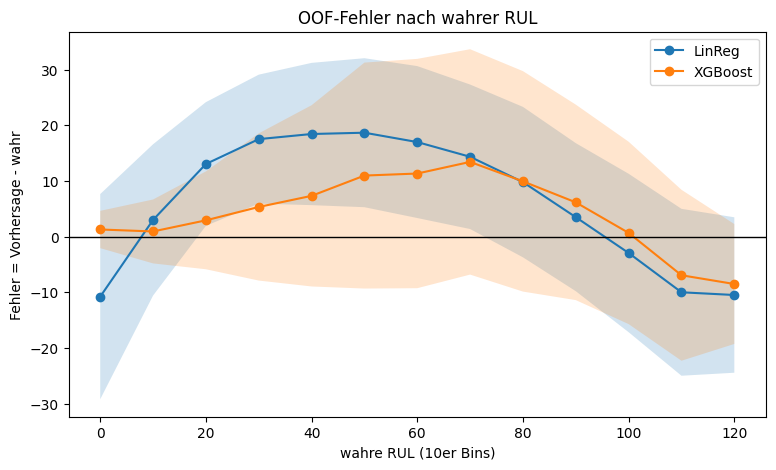

In [27]:
fig, ax = plt.subplots(figsize=(9,5))

x = lr_mittel.index

ax.plot(x, lr_mittel, marker="o", label = "LinReg")
ax.fill_between(x, lr_mittel - lr_std, lr_mittel + lr_std, alpha=0.2)
ax.plot(x, xgb_mittel, marker="o", label="XGBoost")
ax.fill_between(x, xgb_mittel - xgb_std, xgb_mittel+xgb_std, alpha = 0.2)


ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("wahre RUL (10er Bins)")
ax.set_ylabel("Fehler = Vorhersage - wahr")
ax.set_title("OOF-Fehler nach wahrer RUL")
ax.legend()
plt.show()

### Fehleranalyse (Out-of-Fold)

**Vorgehen:** Out-of-Fold-Vorhersagen mit denselben 10 GroupKFold-Splits (`oof_vorhersagen`): Jede Zeile wird von dem Modell vorhergesagt, das ihr Triebwerk nicht gesehen hat. Features: Rolling + Differenz (84). Fehler = Vorhersage − wahre RUL (positiv = zu spät), gruppiert in 10er-Bins der wahren RUL, Mittelwert ± std je Bin.

**Kontrolle:** OOF-RMSE über alle Zeilen: LinReg 18,27 / XGBoost 16,08 vs. CV-Mittel 18,26 / 15,97. Die Abweichung ist erwartet: `run_cv` mittelt die 10 Fold-RMSEs, OOF rechnet einen RMSE über alle Zeilen (die Wurzel ist nicht linear, die Folds sind unterschiedlich groß). Bei XGBoost ist der Abstand größer, weil seine Fold-RMSEs stärker streuen (std 2,09 vs. 0,78).

**Hypothese (vorher):** Der Fehler ist nahe RUL 125 am größten und überwiegend negativ (zu früh) und wird mit sinkender RUL kleiner, weil die Sensoren erst spät einen Trend zeigen.

**Befund:**

| wahre RUL | LinReg | XGBoost |
|---|---|---|
| 0 | ≈ −11 | ≈ +1 |
| größter mittlerer Fehler | ≈ +18,6 bei 50 | ≈ +13,4 bei 70 |
| 110–120 | ≈ −10 | ≈ −7 bis −9 |

- **Bestätigt:** Nahe 125 liegen beide Modelle zu früh. XGBoost ist nahe 0 fast fehlerfrei, mit schmalem Band.
- **Widerlegt:** Der größte mittlere Fehler liegt in der Mitte (LinReg ≈ 50, XGBoost ≈ 70) und ist **positiv, also zu spät**. Das ist die für die Wartung gefährliche Richtung, und hier entstehen die großen Verspätungsfehler, die den NASA-Score treiben (vgl. `03`).
- Bin 120 enthält über 8.000 Zeilen (≈ 40 %), weil alle gekappten Zeilen dort landen.

**Erklärung:** Das Label fällt ab 125 gleichmäßig um 1 pro Zyklus, die Sensoren bleiben aber lange flach und kippen erst spät. Bei wahrer RUL 50–70 sehen sie im Mittel noch eher aus wie im Plateau, deshalb schätzt das Modell zu hoch. Die Streuung zwischen den Triebwerken erklärt das breite Band, aber nicht die systematische Verschiebung des Mittelwerts.
- LinReg zeigt einen Bogen (zu früh → zu spät → zu früh): Ein lineares Modell kann die gekrümmte Beziehung zwischen Sensoren und RUL nicht abbilden. Bei RUL 0 sagt LinReg im Mittel negative Restlaufzeiten voraus (Extrapolation der steilen Sensorverläufe).
- XGBoost bleibt weitgehend im Bereich der Trainingslabels und hat dieses Problem kaum. Der Fehler in der Mitte ist flacher, aber ebenfalls positiv.

**Folgerung:**
- Kappungs-Sensitivität (115 / 125 / 135) prüfen, denn die Kappung bestimmt, wo das Plateau endet.
- Für die Wartungsentscheidung (`05_decision`) die Schwelle eher auf ein unteres Quantil legen statt auf die Punktschätzung.

**Hypothese für Steigung einer Regressionsgeraden als Feature:**

Die Steigung einer Regressionsgeraden gibt im Vergleich zu mean5-mean25 kaum neue Informationen, da diese schon eine Steigung abbilden, welche aufgrund des kleineren Fensters von mean5 aber mehr Rauschen enthält.
These: XGB und LR verbessern sich nur leicht (RMSE sinkt um <=0,5) und nicht in allen Folds.

In [28]:
def steigung(werte):
    """Bekommt ein Fenster von Sensorwerten (Array), gibt die Steigung der Regressionsgeraden pro Zyklus zurück."""
    t = np.arange(len(werte))
    t_abw = t - t.mean()
    x_abw = werte - werte.mean()
    return (((t_abw)*(x_abw)).sum()/((t_abw)**2).sum())

In [29]:
steigung(np.array([3,2,1]))

np.float64(-1.0)

In [30]:
neue_spalte = []

for col in FEATURES:
    name = f"{col}_slope25"
    train[name] = (
        train.groupby("unit")[col]
            .transform(lambda s: s.rolling(25, min_periods = 25).apply(steigung, raw = True))
            .fillna(0)
    )
    neue_spalte.append(name)

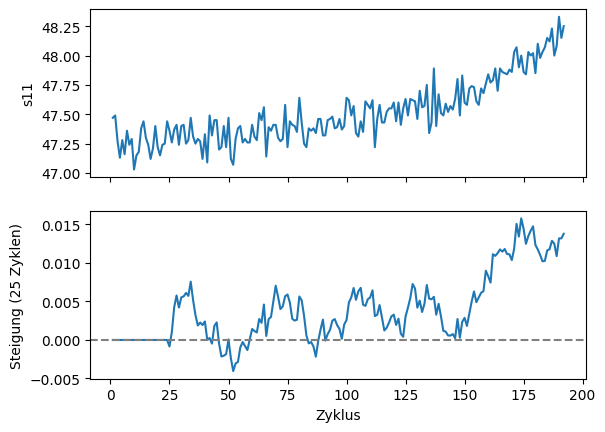

In [31]:
eng = train[train["unit"] == 1]

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)

ax1.plot(eng["cycle"], eng["s11"])
ax1.set_ylabel("s11")

ax2.plot(eng["cycle"], eng["s11_slope25"])
ax2.axhline(0, color="gray", linestyle="--")
ax2.set_ylabel("Steigung (25 Zyklen)")
ax2.set_xlabel("Zyklus")

plt.show()

In [32]:
feature_cols_c = feature_cols_b + neue_spalte
len(feature_cols_c)

98

In [33]:
train[neue_spalte].isna().sum().sum()

np.int64(0)

In [34]:
X4 = train[feature_cols_c]
cv_roll_c_lr = run_cv(LinearRegression(), X4, y, splits)
cv_roll_c_xgb = run_cv(XGBRegressor(), X4, y, splits)

In [35]:
(cv_roll_c_lr["rmse_val"]<cv_roll_b_lr["rmse_val"]).sum()

np.int64(10)

In [36]:
(cv_roll_c_xgb["rmse_val"]<cv_roll_b_xgb["rmse_val"]).sum()

np.int64(10)

In [37]:
cv_roll_c_xgb.drop(columns="fold").agg(["mean", "std"])

,rmse_train,rmse_val,nasa_val,bias,anteil_spaet,max_spaet
mean,3.565880,14.132025,4.223489,-0.356407,0.458818,56.349945
std,0.102795,1.701683,1.407172,1.290083,0.039163,6.056059


In [38]:
cv_roll_c_lr.drop(columns="fold").agg(["mean", "std"])

,rmse_train,rmse_val,nasa_val,bias,anteil_spaet,max_spaet
mean,16.538740,16.962324,4.684309,0.040573,0.504639,47.692023
std,0.073581,0.683680,0.542335,1.209884,0.036387,3.835720


In [39]:
train.groupby("unit")["cycle"].diff().dropna().eq(1).all()

np.True_

In [40]:
fenster = train[(train["unit"]==1)& (train["cycle"] >= 76) & (train["cycle"]<= 100)]["s11"].values

print(len(fenster))

print(steigung(fenster))

print(train[(train["unit"]==1)& (train["cycle"]==100)]["s11_slope25"].values)

25
0.002592307692307729
[0.00259231]


**Ergebnis Steigung (Fenster 25, `min_periods=25`, 98 Features):**

| | b: Rolling + Differenz | c: + Steigung |
|---|---|---|
| LinReg RMSE / NASA | 18,26 / 6,04 | 16,96 ± 0,68 / 4,68 |
| XGBoost RMSE / NASA | 15,97 / 6,62 | 14,13 ± 1,70 / 4,22 |
| Folds besser | | 10/10 bei beiden |

→ **Hypothese widerlegt** (erwartet ≤ 0,5 und nicht in allen Folds): XGBoost −1,84, LinReg −1,30, jeweils 10/10 Folds.
→ **Leakage geprüft:** `train` je Triebwerk lückenlos nach Zyklus sortiert, Handprüfung Triebwerk 1 / Zyklus 100 (Zyklen 76–100) identisch.
→ **Erklärung:**
- `mean5 − mean25` erbt das Rauschen von `mean5` (nur 5 Werte). Die Steigung nutzt alle 25 Punkte mit Kleinste-Quadrate-Gewichten → deutlich rauschärmere Trendschätzung.
- Für LinReg ist die Steigung eine neue Richtung: Sie gewichtet die 25 Werte als Rampe, `mean5 − mean25` als Treppe. Eine Rampe lässt sich aus `mean5`, `mean25` und dem aktuellen Wert nicht bilden.
→ **`min_periods=25` statt 5:** Mit weniger Punkten rauscht die Steigung so stark, dass am Triebwerksanfang Ausschläge bis −0,07 entstehen (Plot Triebwerk 1). Die ersten 24 Zeilen werden 0 gesetzt (gesundes Triebwerk, liegt im gekappten Bereich).
→ **Offen:** XGBoost überfittet weiter (Train 3,57 vs. Val 14,13) → Tuning · Fehleranalyse mit c wiederholen: Bleibt der Bogen bei LinReg?

In [41]:
oof_b_lr = oof_vorhersagen(LinearRegression(),X3, y, splits)
oof_c_lr = oof_vorhersagen(LinearRegression(), X4, y, splits)

oof_b_xgb = oof_vorhersagen(XGBRegressor(), X3, y, splits)
oof_c_xgb = oof_vorhersagen(XGBRegressor(), X4, y, splits)


In [42]:
fehler_plot_b = pd.DataFrame({
    "RUL": y,
    "fehler_lr": oof_b_lr-y,
    "fehler_xgb": oof_b_xgb-y,
    "bin": (y//10)*10

})

fehler_plot_c = pd.DataFrame({
    "RUL": y,
    "fehler_lr": oof_c_lr-y,
    "fehler_xgb": oof_c_xgb-y,
    "bin": (y//10)*10

})

In [43]:
gruppen_b = fehler_plot_b.groupby("bin")

lr_mittel_b = gruppen_b["fehler_lr"].mean()
lr_std_b = gruppen_b["fehler_lr"].std()
anzahl = gruppen_b["RUL"].count()

xgb_mittel_b = gruppen_b["fehler_xgb"].mean()
xgb_std_b = gruppen_b["fehler_xgb"].std()


gruppen_c = fehler_plot_c.groupby("bin")

lr_mittel_c = gruppen_c["fehler_lr"].mean()
lr_std_c = gruppen_c["fehler_lr"].std()

xgb_mittel_c = gruppen_c["fehler_xgb"].mean()
xgb_std_c = gruppen_c["fehler_xgb"].std()
anzahl = gruppen_c["RUL"].count()


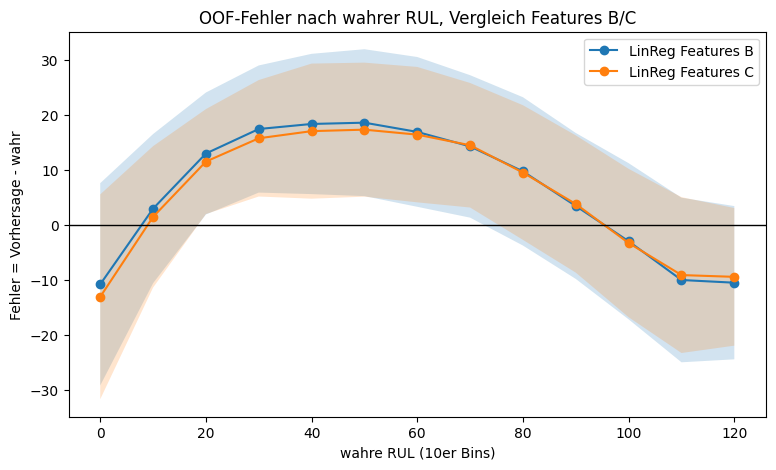

In [44]:
fig, ax = plt.subplots(figsize=(9,5))

x = lr_mittel_b.index

ax.plot(x, lr_mittel_b, marker="o", label = "LinReg Features B")
ax.fill_between(x, lr_mittel_b - lr_std_b, lr_mittel_b + lr_std_b, alpha=0.2)
ax.plot(x, lr_mittel_c, marker="o", label="LinReg Features C")
ax.fill_between(x, lr_mittel_c - lr_std_c, lr_mittel_c+lr_std_c, alpha = 0.2)


ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("wahre RUL (10er Bins)")
ax.set_ylabel("Fehler = Vorhersage - wahr")
ax.set_title("OOF-Fehler nach wahrer RUL, Vergleich Features B/C")
ax.legend()
plt.show()

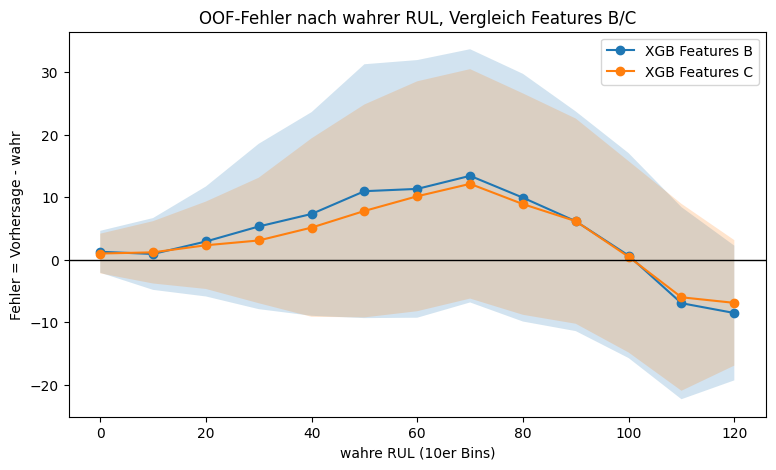

In [45]:
fig, ax = plt.subplots(figsize=(9,5))

x = xgb_mittel_b.index

ax.plot(x, xgb_mittel_b, marker="o", label = "XGB Features B")
ax.fill_between(x, xgb_mittel_b - xgb_std_b, xgb_mittel_b + xgb_std_b, alpha=0.2)
ax.plot(x, xgb_mittel_c, marker="o", label="XGB Features C")
ax.fill_between(x, xgb_mittel_c - xgb_std_c, xgb_mittel_c+xgb_std_c, alpha = 0.2)


ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("wahre RUL (10er Bins)")
ax.set_ylabel("Fehler = Vorhersage - wahr")
ax.set_title("OOF-Fehler nach wahrer RUL, Vergleich Features B/C")
ax.legend()
plt.show()

In [46]:
anteil = anzahl/anzahl.sum()
beitrag_b_lr = anteil*(np.square(lr_mittel_b)+np.square(lr_std_b))

beitrag_c_lr = anteil*(np.square(lr_mittel_c)+np.square(lr_std_c))

beitrag_b_xgb = anteil*(np.square(xgb_mittel_b)+np.square(xgb_std_b))

beitrag_c_xgb = anteil*(np.square(xgb_mittel_c)+np.square(xgb_std_c))

In [47]:
oof_rmse_b_lr = np.sqrt(beitrag_b_lr.sum())
oof_rmse_c_lr = np.sqrt(beitrag_c_lr.sum())
oof_rmse_b_xgb = np.sqrt(beitrag_b_xgb.sum())
oof_rmse_c_xgb = np.sqrt(beitrag_c_xgb.sum())

print(f"RMSE LR b:{oof_rmse_b_lr:.2f} RMSE LR c: {oof_rmse_c_lr:.2f} RMSE XGB b: {oof_rmse_b_xgb:.2f} RMSE XGB c: {oof_rmse_c_xgb:.2f}")

RMSE LR b:18.28 RMSE LR c: 16.98 RMSE XGB b: 16.09 RMSE XGB c: 14.23


In [48]:
differenz_lr = beitrag_b_lr - beitrag_c_lr
differenz_xgb = beitrag_b_xgb - beitrag_c_xgb

print(differenz_lr)
print(differenz_xgb)

bin
0      -3.050807
10      1.232118
20      3.307697
30      3.771085
40      2.824059
50      3.673815
60      2.457837
70      1.625408
80      1.756065
90      0.867201
100     0.859758
110     1.955213
120    24.684476
dtype: float64
bin
0       0.086987
10      0.367718
20      1.531877
30      4.499939
40      4.287080
50      8.789179
60      5.410815
70      5.142414
80      4.756629
90      1.889252
100     1.676221
110     1.191876
120    16.894830
dtype: float64


In [49]:
differenz_lr.loc[120]/differenz_lr.sum()

np.float64(0.5370402063499252)

In [50]:
differenz_xgb.loc[120]/differenz_xgb.sum()

np.float64(0.2988922542851146)

In [51]:
differenz_lr.loc[20:80]/differenz_lr.sum()

bin
20    0.071963
30    0.082044
40    0.061441
50    0.079928
60    0.053473
70    0.035363
80    0.038205
dtype: float64

In [52]:
differenz_xgb.loc[20:80]/differenz_xgb.sum()


bin
20    0.027101
30    0.079610
40    0.075844
50    0.155492
60    0.095725
70    0.090976
80    0.084151
dtype: float64

In [53]:
(differenz_xgb.loc[20:80]/differenz_xgb.sum()).sum()


np.float64(0.6088995056139355)

### Fehleranalyse (OOF) mit Basis c – woher kommt die Verbesserung?

**Erwartung vorher:** Der LinReg-Bogen (zu spät in der Mitte, zu früh an den Rändern) bleibt, flacht durch die Steigung aber leicht ab.

**Ergebnis** (OOF, dieselben 10 GroupKFold-Splits, MacBook):

| | OOF-RMSE b | OOF-RMSE c | Anteil der MSE-Verbesserung aus Bin 120 |
|---|---|---|---|
| LinReg | 18,27 | 16,95 | 53,6 % |
| XGBoost | 15,89 | 14,17 | 40,9 % (Mitte 20–80: 55,9 %) |

- **LinReg:** Der Bogen bleibt. Das Maximum sinkt nur leicht (RUL 50: ≈ 18,5 → ≈ 17,3), bei RUL 0 wird der Fehler sogar größer (≈ −10,8 → ≈ −13).
- **XGBoost:** Der Verspätungsfehler in der Mitte sinkt um etwa 2 Zyklen (RUL 40: ≈ 7,2 → ≈ 4,9 · RUL 70: ≈ 13,2 → ≈ 11,2), die Streuung dort ebenfalls.
- **Zerlegung:** MSE = Σ Anteil_Bin × (Bias_Bin² + Std_Bin²). Bin 120 enthält alle gekappten Zeilen, das sind etwa 42 % der Daten, jeder andere Bin nur 1000 Zeilen. Der Plot gewichtet jeden Bin gleich und täuscht damit.
- **Deutung:** Ein großer Teil der RMSE-Verbesserung entfällt auf gesunde Triebwerke, also auf die harmlose Richtung „zu früh“. Warum gerade dort? → Weil die Steigung dem Modell zeigt wo wirklich eine Veränderung der Sensoren stattfindet und das Rauschen minimiert.
- **Für die Instandhaltung** zählt die Mitte. Die NASA-Verbesserung kommt vermutlich aus weniger stark verspäteten Fehlern (noch ungeprüft, z. B. Anteil `fehler > 30` in b gegenüber c).
- **Hinweis:** Werte sind aus Sitzung mit MacBook, müssen entsprechend angepasst werden beim finalen Lauf auf mac mini

Hypothese: Die Normalisierung verbessert den RMSE bei LinReg und XGBoost jeweils um mehr als 0,5, in mindestens 8 von 10 Folds. Widerlegt, wenn eines der beiden Modelle darunter bleibt.
Grund dafür ist die verbesserte Deutung der Sensorwerte da sowohl LinReg als auch XGB die Startwerte der Sensoren kennen und die einzelnen Werte so besser deuten können.

In [54]:
t1 = train[train["unit"]==1].copy()

s11_frueh = t1["s11"].where(t1["cycle"]<=20)

t1["s11_start"] = s11_frueh.expanding().mean()

t1["s11_norm"] = t1["s11"] - t1["s11_start"]


In [55]:
zeilen = t1["cycle"].isin([1,2,3,19,20,21,22])
print(t1.loc[zeilen, ["cycle", "s11", "s11_start", "s11_norm"]])
print(t1["s11"].iloc[:3].mean())

    cycle    s11  s11_start  s11_norm
0       1  47.47  47.470000  0.000000
1       2  47.49  47.480000  0.010000
2       3  47.27  47.410000 -0.140000
18     19  47.40  47.270526  0.129474
19     20  47.22  47.268000 -0.048000
20     21  47.15  47.268000 -0.118000
21     22  47.24  47.268000 -0.028000
47.410000000000004


In [56]:
frueh = train["s11"].where(train["cycle"]<= 20)
train["s11_start"] = frueh.groupby(train["unit"]).transform(lambda s: s.expanding().mean())

In [57]:
np.allclose(train.loc[train["unit"]==1, "s11_start"], t1["s11_start"])

True

In [58]:
niveau_cols = []
for col in feature_cols:
    if "std" not in col:
        niveau_cols.append(col)

norm_namen = []

for col in niveau_cols:
    frueh = train[col].where(train["cycle"]<=20)
    train[f"{col}_start"] = frueh.groupby(train["unit"]).transform(lambda s: s.expanding().mean())
    
    train[f"{col}_norm"] = train[col] - train[f"{col}_start"]

    norm_namen.append(f"{col}_norm")

/var/folders/gp/txrpfq654vg3q7bdjgtj7t980000gn/T/ipykernel_96356/3465923041.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train[f"{col}_norm"] = train[col] - train[f"{col}_start"]
/var/folders/gp/txrpfq654vg3q7bdjgtj7t980000gn/T/ipykernel_96356/3465923041.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train[f"{col}_start"] = frueh.groupby(train["unit"]).transform(lambda s: s.expanding().mean())
/var/folders/gp/txrpfq654vg3q7bdjgtj7t980000gn/T/ipykernel_96356/3465923041.py:12: PerformanceWarning: DataFrame is highly 

In [59]:
np.allclose(train.loc[train["unit"]==1, "s11_start"], t1["s11_start"])

True

In [60]:
train.filter(like="_start").isna().sum().sum()

np.int64(0)

In [61]:
len(niveau_cols)
len(norm_namen)

42

In [62]:
train[norm_namen].isna().sum().sum()

np.int64(0)

In [63]:
train[train["cycle"]==1][norm_namen].abs().max()

s2_norm            0.0
s3_norm            0.0
s4_norm            0.0
s8_norm            0.0
s11_norm           0.0
s13_norm           0.0
s15_norm           0.0
s17_norm           0.0
s7_norm            0.0
s12_norm           0.0
s20_norm           0.0
s21_norm           0.0
s9_norm            0.0
s14_norm           0.0
s2_mean5_norm      0.0
s2_mean25_norm     0.0
s3_mean5_norm      0.0
s3_mean25_norm     0.0
s4_mean5_norm      0.0
s4_mean25_norm     0.0
s8_mean5_norm      0.0
s8_mean25_norm     0.0
s11_mean5_norm     0.0
s11_mean25_norm    0.0
s13_mean5_norm     0.0
s13_mean25_norm    0.0
s15_mean5_norm     0.0
s15_mean25_norm    0.0
s17_mean5_norm     0.0
s17_mean25_norm    0.0
s7_mean5_norm      0.0
s7_mean25_norm     0.0
s12_mean5_norm     0.0
s12_mean25_norm    0.0
s20_mean5_norm     0.0
s20_mean25_norm    0.0
s21_mean5_norm     0.0
s21_mean25_norm    0.0
s9_mean5_norm      0.0
s9_mean25_norm     0.0
s14_mean5_norm     0.0
s14_mean25_norm    0.0
dtype: float64

In [64]:
np.allclose(train.loc[train["unit"]==1, "s11_norm"], t1["s11_norm"])

True

In [65]:
feature_cols_d = []

for col in feature_cols_c:
    if col not in niveau_cols:
        feature_cols_d.append(col)

feature_cols_d = feature_cols_d + norm_namen

In [66]:
len(feature_cols_d)

98

## Basis d: Normalisierung je Triebwerk auf den Startzustand

**Idee:** Laut C-MAPSS starten die Triebwerke mit unterschiedlichem Anfangsverschleiß und unterschiedlicher Fertigungsstreuung, ihre Sensorniveaus unterscheiden sich also schon im Neuzustand. Zieht man den Startwert ab, messen die Features die Veränderung seit dem Start statt des absoluten Niveaus.

**Umsetzung**
- Startwert = Mittelwert der ersten k = 20 Zyklen je Triebwerk. Das kürzeste Test-Triebwerk hat 31 Zyklen, k = 20 liegt also sicher in der gesunden Phase.
- Ohne Leakage: `.where(cycle <= 20)` + `.expanding().mean()` je Triebwerk. Bis Zyklus 20 fließen nur vergangene Zyklen ein, danach bleibt der Startwert konstant.
- Betroffen sind nur die Niveau-Features: Rohwert, `mean5` und `mean25` je Sensor, also 42 von 98. Jede Spalte zieht ihren eigenen Startwert ab. Differenz, `std` und Steigung ändern sich nicht, weil sich eine Konstante darin kürzt oder keine Rolle spielt.
- d **ersetzt** die 42 Niveau-Spalten und hat damit wie c 98 Features. Die Ablation misst so nur die Normalisierung.

**Kontrollen:** 42/42 Spalten · 0 NaN · Zyklus 1 bei allen Triebwerken exakt 0 · `s11_norm` aus der Schleife = Einzeltest an Triebwerk 1 (Startwert ab Zyklus 20 konstant 47,268) · `feature_cols_d` mit 98 Spalten, ohne Duplikate und ohne alte Niveau-Spalten, `feature_cols_c` unverändert

In [67]:
X5 = train[feature_cols_d]

run_cv(LinearRegression(),X4, y, splits).agg("mean")
run_cv(XGBRegressor(),X4, y, splits).agg("mean")

fold             4.500000
rmse_train       3.565880
rmse_val        14.132025
nasa_val         4.223489
bias            -0.356407
anteil_spaet     0.458818
max_spaet       56.349945
dtype: float64

In [68]:
cv_roll_d_lr = run_cv(LinearRegression(),X5, y, splits).agg("mean")
cv_roll_d_xgb = run_cv(XGBRegressor(),X5, y, splits).agg("mean")

In [69]:
(cv_roll_d_lr["rmse_val"]<cv_roll_c_lr["rmse_val"]).sum()

np.int64(0)

In [70]:
(cv_roll_d_xgb["rmse_val"]<cv_roll_c_xgb["rmse_val"]).sum()

np.int64(5)

In [71]:
cv_roll_d_lr

fold             4.500000
rmse_train      16.014885
rmse_val        18.377505
nasa_val         6.426273
bias            -0.177775
anteil_spaet     0.442959
max_spaet       47.391925
dtype: float64

In [72]:
cv_roll_d_xgb

fold             4.500000
rmse_train       2.688694
rmse_val        14.375397
nasa_val         4.080645
bias            -0.714874
anteil_spaet     0.449739
max_spaet       52.493288
dtype: float64

### Ablation d gegen c

**Hypothese (vor dem Lauf):** Die RMSE beider Modelle wird in ≥ 8/10 Folds um mehr als 0,5 besser. Begründung: Die Normalisierung entfernt das individuelle Ausgangsniveau. Ohne sie kann derselbe Sensorwert bei verschiedenen Triebwerken einen unterschiedlichen Verschleißzustand bedeuten, und die Modelle kennen den Startwert nicht, weil das Triebwerk kein Feature ist.

| | RMSE c | RMSE d | NASA c | NASA d | Folds mit d < c |
|---|---|---|---|---|---|
| LinReg | 16,96 | 18,38 | 4,68 | 6,43 | 0/10 |
| XGBoost | 14,13 | 14,38 | 4,22 | 4,08 | 5/10 |

→ **Hypothese widerlegt.**
- **LinReg** wird in allen Folds schlechter und fällt fast auf Basis b zurück (18,26). Der Gewinn durch die Steigung ist damit praktisch weg.
- **XGBoost** bleibt neutral, 5/10 Folds sind ein Münzwurf. Der NASA-Score sinkt leicht, wahrscheinlich weil sich die Vorhersagen nach früh verschieben (Bias d: −0,71, Vergleich mit c offen). Ein besserer NASA-Score allein ist also kein besseres Modell.
- **Overfitting XGBoost wächst:** Train 3,57 → 2,69 bei gleicher Val-RMSE.

In [73]:
start = (train["s11"]-train["s11_norm"]).groupby(train["unit"]).last()
lebensdauer = train.groupby("unit")["cycle"].max()

In [74]:
pearsonr(start, lebensdauer)

PearsonRResult(statistic=np.float64(-0.21598371724728493), pvalue=np.float64(0.030910331226459843))

In [75]:
sig = train[train["cycle"]<=20].groupby("unit")["s11"].agg("std")

In [76]:
sig_mean = sig.mean()

In [77]:
schaetzfehler = sig_mean/np.sqrt(20)

In [78]:
start.std()/schaetzfehler

np.float64(6.676203422049265)

### Warum schadet die Normalisierung?

Die Hypothese hat den Startwert als reine Störung behandelt. Dazu habe ich zwei Mechanismen auf Triebwerksebene geprüft (n = 100, Sensor `s11`):

**1. Der Startwert trägt RUL-Information:** Mehr Anfangsverschleiß führt zu kürzerer Lebensdauer.
Korrelation Startwert gegen Lebensdauer: **r = −0,215, p = 0,03**. Richtung bestätigt und signifikant, aber schwach (r² ≈ 5 %). Erwartet hatte ich vorab r > 0,8.

**2. Der Startwert ist zu ungenau geschätzt:** Der Mittelwert aus 20 Zyklen hat einen Fehler von σ/√20, und dieser wird von jeder Zeile abgezogen.
Streuung² der Startwerte = echte Unterschiede² + (σ/√20)², der Rauschanteil ist also 1/Verhältnis².
Hypothese: relevant ab einem Verhältnis ≤ 2,5. Ergebnis: **6,67**, Rauschanteil ≈ 2 % → **widerlegt**.

**Fazit:** Die Startniveaus sind zu ≈ 98 % echte Unterschiede zwischen den Triebwerken und tragen RUL-Information. Die Normalisierung entfernt also Signal statt Störung. **c bleibt die Basis** für den Modellvergleich.

**Modellvergleich:**

In [79]:
ridge_pipe = make_pipeline(StandardScaler(), Ridge())

lgbm = run_cv(LGBMRegressor(verbose = -1), X4, y, splits)
xgb = run_cv(XGBRegressor(),X4,y,splits)
lr = run_cv(LinearRegression(), X4, y, splits)
rf = run_cv(RandomForestRegressor(n_jobs=-1, random_state=42),X4,y,splits)
ridge = run_cv(ridge_pipe,X4,y,splits)


### Modellvergleich auf Basis c – Hypothese (vor dem Lauf)

**Setup:** 10 GroupKFold-Splits, Basis c (98 Features), alle Modelle mit Default-Parametern (`random_state=42`, `n_jobs=-1` beim RF) · Referenz: LinReg und XGB im selben Lauf

| Modell | Vorhersage | Begründung |
|---|---|---|
| **Ridge** (mit `StandardScaler` in der Pipeline) | RMSE_val um > 0,5 kleiner als LinReg | Der Strafterm stabilisiert die Koeffizienten der stark korrelierten Features (Rohwert, `mean5`, `mean25` je Sensor) |
| **LightGBM** | RMSE_val um > 0,3 kleiner als XGB · RMSE_train um > 0,5 höher als XGB | Kleinere Learning Rate (0,1 statt 0,3) → bei gleicher Anzahl Bäume weniger Anpassung an die Trainingsdaten → weniger Overfitting |
| **RandomForest** | RMSE_val um ≥ 0,5 kleiner als XGB | Der Mittelwert vieler Bäume reduziert die Varianz und damit das Overfitting |

**Entscheidungsregel:** Ein Modell löst XGB ab, wenn
1. die mittlere RMSE_val um ≥ 0,5 niedriger ist **und**
2. die RMSE_val in ≥ 8/10 Folds niedriger ist **und**
3. der NASA-Score nicht schlechter wird.

Schaffen es mehrere Modelle, gewinnt das mit dem besten NASA-Score, weil er späte Vorhersagen stärker bestraft und das für die Wartung die gefährliche Richtung ist. Schafft es keins, bleibt XGB.

In [80]:
lgbm.agg("mean")

fold             4.500000
rmse_train       6.643371
rmse_val        13.241206
nasa_val         3.602103
bias            -0.102583
anteil_spaet     0.461161
max_spaet       54.221874
dtype: float64

In [81]:
rf.agg("mean")

fold             4.500000
rmse_train       3.104731
rmse_val        13.459340
nasa_val         3.625276
bias            -0.240784
anteil_spaet     0.392082
max_spaet       53.155000
dtype: float64

In [82]:
ridge.agg("mean")

fold             4.500000
rmse_train      16.538741
rmse_val        16.962019
nasa_val         4.684090
bias             0.040522
anteil_spaet     0.504590
max_spaet       47.691088
dtype: float64

In [83]:
lr.agg("mean")

fold             4.500000
rmse_train      16.538740
rmse_val        16.962324
nasa_val         4.684309
bias             0.040573
anteil_spaet     0.504639
max_spaet       47.692023
dtype: float64

In [84]:
xgb.agg("mean")

fold             4.500000
rmse_train       3.565880
rmse_val        14.132025
nasa_val         4.223489
bias            -0.356407
anteil_spaet     0.458818
max_spaet       56.349945
dtype: float64

In [85]:
(lgbm["rmse_val"]<xgb["rmse_val"]).sum()

np.int64(10)

In [86]:
(rf["rmse_val"]<xgb["rmse_val"]).sum()

np.int64(9)

In [87]:
(lgbm["rmse_val"]<rf["rmse_val"]).sum()

np.int64(6)

### Modellvergleich auf Basis c – Ergebnis

**Mittelwerte über 10 GroupKFold-Folds** (Lauf auf dem MacBook, finale Werte beim Run All auf dem Mac mini)

| Modell | RMSE_train | RMSE_val | NASA | Bias | Anteil spät | Max. spät | Folds besser als XGB |
|---|---|---|---|---|---|---|---|
| LinReg | 16,54 | 16,94 | 4,67 | −0,003 | 50,3 % | 48,1 | – |
| Ridge | 16,54 | 16,94 | 4,67 | −0,003 | 50,2 % | 48,1 | – |
| XGB (Referenz) | 3,57 | 14,08 | 4,09 | −0,38 | 46,0 % | 55,9 | – |
| RandomForest | 3,10 | 13,43 | 3,62 | −0,25 | 38,9 % | 54,7 | 9/10 |
| **LightGBM** | 6,65 | **13,08** | **3,45** | −0,23 | 45,8 % | 55,7 | **10/10** |

#### Hypothesen-Check

- **Ridge (> 0,5 besser als LinReg) → widerlegt.** Der Unterschied ist praktisch null (Δ ≈ 0,0003). LinReg overfittet nicht, die Lücke Train/Val beträgt nur 0,4. Der Fehler ist also Bias, kein Varianzproblem, und der Strafterm hat nichts zu korrigieren. Dazu ist `alpha=1` bei ca. 18.500 Trainingszeilen vernachlässigbar.
- **LightGBM (Val > 0,3 besser, Train > 0,5 höher als XGB) → bestätigt.** Val ist um 1,00 besser, Train um 3,08 höher. Die Lücke Train/Val schrumpft von 10,5 auf 6,4, was zum Mechanismus „kleinere Learning Rate → weniger Overfitting“ passt. Der bessere NASA-Score entsteht nicht durch eine Verschiebung nach früh, denn der Bias liegt näher an 0 (−0,38 → −0,23). *Einschränkung:* LightGBM unterscheidet sich nicht nur in der Learning Rate, sondern lässt die Bäume auch blattweise wachsen und hat andere Defaults. Der Mechanismus ist deshalb plausibel, aber nicht isoliert nachgewiesen.
- **RandomForest (≥ 0,5 besser als XGB) → bestätigt.** Val ist um 0,66 besser. Die Train-RMSE liegt mit 3,10 sogar unter XGB, trotzdem ist Val besser: Das Mitteln vieler Bäume senkt die Varianz.

#### Entscheidungsregel

| Kriterium | LightGBM | RandomForest |
|---|---|---|
| Mittlere RMSE_val ≥ 0,5 niedriger als XGB | −1,00 ✓ | −0,66 ✓ |
| RMSE_val in ≥ 8/10 Folds niedriger | 10/10 ✓ | 9/10 ✓ |
| NASA nicht schlechter | 3,45 ✓ | 3,62 ✓ |

Beide lösen XGB ab → Gleichstand nach NASA → **LightGBM**.

#### Entscheidung

- **LightGBM ist das Modell für das Tuning.**
- Der Direktvergleich mit RandomForest ist knapp (0,34 RMSE, 7/10 Folds). RF bleibt deshalb ein Kandidat, falls das Tuning die Reihenfolge verschiebt.
- Nebenbefund für die Entscheidungsebene: RandomForest hat den geringsten Anteil später Vorhersagen (38,9 %).
- *Grenze:* Verglichen wurden Default-Parameter, also die Voreinstellung der Modelle, nicht ihre beste Version nach dem Tuning.

In [88]:
from pathlib import Path

ordner = Path("../data/processed")
ordner.mkdir(parents=True, exist_ok=True)

spalten = ["unit", "RUL"] + feature_cols_c
train[spalten].to_pickle(ordner / "fd001_basis_c.pkl")

***Check von features.py***

In [89]:
train_roh, test_roh, RUL_roh = load_fd001()
train_roh = add_rul(train_roh, cap =125)

In [90]:
train_neu, feature_cols_neu = build_features(train_roh)

In [91]:
feature_cols_neu == feature_cols_c

True

In [ ]:
spalten1 = ["unit", "RUL"] + feature_cols_neu
ref = pd.read_pickle("../data/processed/fd001_basis_c.pkl")
pd.testing.assert_frame_equal(train_neu[spalten1], ref)

In [93]:
"s2_mean5" in train_roh.columns

False

**Hinweis zum Feature-Code (29.10.):** Der Code oben bleibt als Dokumentation der schrittweisen Ablation unverändert, und das Pickle `fd001_basis_c.pkl` wird weiter mit dieser Notebook-Version erzeugt. Für `train.py` und den Testlauf liegt derselbe Code ausgelagert in `src/features.py` (`add_rolling`, `add_diff`, `add_slope`, `build_features`). Der Vergleich ganz unten in diesem Notebook stellt sicher, dass beide Versionen identisch sind: gleiche 98 Spalten in gleicher Reihenfolge, Werte exakt gleich (`assert_frame_equal` ohne Toleranz), Eingabe-DataFrame unverändert.